# HW3 — Exploratory Data Analysis & Cleaning

**Santander Customer Transaction Prediction.** This notebook investigates the data quality of `train.csv` and `test.csv` before any modeling. The Kaggle test set is known to contain a substantial fraction of synthetic rows, so this notebook also detects and isolates them.

Outputs (saved to `artifacts/`):
- `test_is_real.csv` — per-test-row flag indicating whether the row is real or synthetic
- `feature_diagnostics.csv` — per-feature statistics (skew, univariate AUC, KS drift)

Sections:
1. Load + profile
2. Target + per-feature distributions
3. Duplicates + value-count anomalies
4. Synthetic-data detection (unique-value signatures)
5. Outlier scan
6. Univariate leakage scan
7. Train vs test drift (Kolmogorov–Smirnov)
8. Persist artifacts

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score

import warnings
warnings.filterwarnings('ignore')

DATA_DIR = 'data'
ART_DIR = 'artifacts'
os.makedirs(ART_DIR, exist_ok=True)

RANDOM_STATE = 42
sns.set_style('whitegrid')
pd.set_option('display.max_columns', 20)

## 1. Load + Profile

In [2]:
feature_cols = [f'var_{i}' for i in range(200)]
train_dtypes = {c: np.float32 for c in feature_cols} | {'target': np.int8}
test_dtypes = {c: np.float32 for c in feature_cols}

df_train = pd.read_csv(f'{DATA_DIR}/train.csv', dtype=train_dtypes)
df_test = pd.read_csv(f'{DATA_DIR}/test.csv', dtype=test_dtypes)

print(f'Train: {df_train.shape}  ({df_train.memory_usage(deep=True).sum() / 1e6:.1f} MB)')
print(f'Test:  {df_test.shape}  ({df_test.memory_usage(deep=True).sum() / 1e6:.1f} MB)')
df_train.head()

Train: (200000, 202)  (172.3 MB)
Test:  (200000, 201)  (171.9 MB)


,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.522699,-2.3978,7.8784,8.5635,12.780300,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.430500,2.0339,8.1267,8.7889,18.356001,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.604200,3.1417,-6.5213,8.2675,14.722200,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.034700,-1.2706,-2.9275,10.2922,17.969700,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.287600,-1.5121,3.9267,9.5031,17.997400,-8.8104


In [3]:
# Missingness, dtype counts, ID uniqueness
print(f'Train missing cells: {df_train.isnull().sum().sum()}')
print(f'Test missing cells:  {df_test.isnull().sum().sum()}')
print(f'\nTrain ID_code unique: {df_train.ID_code.is_unique}')
print(f'Test ID_code unique:  {df_test.ID_code.is_unique}')
print(f'\nTrain feature dtypes: {set(df_train[feature_cols].dtypes.astype(str))}')
print(f'Test feature dtypes:  {set(df_test[feature_cols].dtypes.astype(str))}')

Train missing cells: 0
Test missing cells:  0

Train ID_code unique: True
Test ID_code unique:  True

Train feature dtypes: {'float32'}
Test feature dtypes:  {'float32'}


In [4]:
# Quick summary stats across the 200 features
desc = df_train[feature_cols].describe().T
print('Per-feature summary (transposed, first 8 features):')
desc.head(8)

Per-feature summary (transposed, first 8 features):


,count,mean,std,min,25%,50%,75%,max
var_0,200000.0,10.679914,3.039990,0.408400,8.453850,10.52475,12.758200,20.315001
var_1,200000.0,-1.627622,4.049967,-15.043400,-4.740025,-1.60805,1.358625,10.376800
var_2,200000.0,10.715193,2.640832,2.117100,8.722475,10.58000,12.516700,19.353001
var_3,200000.0,6.796529,2.043276,-0.040200,5.254075,6.82500,8.324100,13.188300
var_4,200000.0,11.078333,1.623114,5.074800,9.883175,11.10825,12.261125,16.671400
var_5,200000.0,-5.065318,7.863115,-32.562599,-11.200350,-4.83315,0.924800,17.251600
var_6,200000.0,5.408949,0.866585,2.347300,4.767700,5.38510,6.003000,8.447700
var_7,200000.0,16.545849,3.418009,5.349700,13.943800,16.45680,19.102900,27.691799


## 2. Target + Per-Feature Distributions

target
0    179902
1     20098
Name: count, dtype: int64

Positive-class proportion: 10.05%


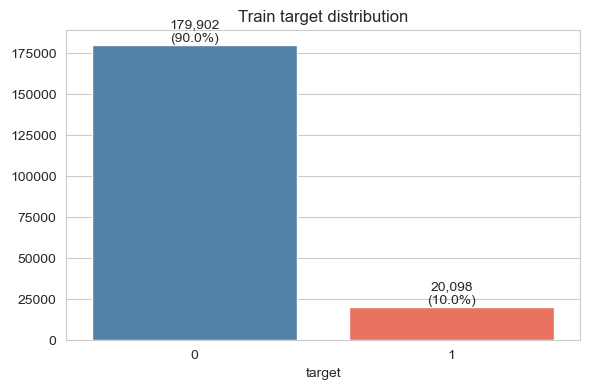

In [5]:
target_counts = df_train['target'].value_counts().sort_index()
target_pct = df_train['target'].value_counts(normalize=True).sort_index() * 100
print(target_counts)
print(f'\nPositive-class proportion: {target_pct[1]:.2f}%')

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=target_counts.index, y=target_counts.values, palette=['steelblue', 'tomato'], ax=ax)
for i, v in enumerate(target_counts.values):
    ax.text(i, v, f'{v:,}\n({target_pct.iloc[i]:.1f}%)', ha='center', va='bottom')
ax.set_title('Train target distribution')
ax.set_xlabel('target')
plt.tight_layout()
plt.show()

Mean |skew|:   0.084
Median |skew|: 0.069
Max |skew|:    0.340
Features with |skew| > 1: 0 / 200


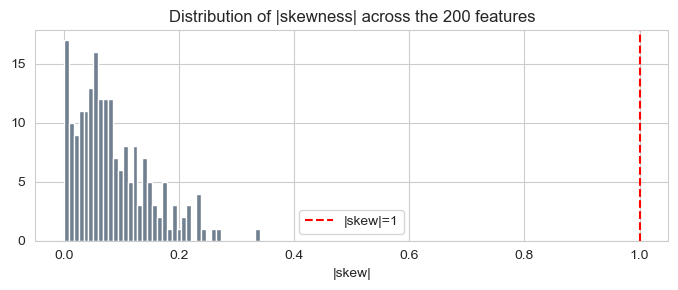

In [6]:
# Skewness across all 200 features
skew_vals = df_train[feature_cols].skew().abs()
print(f'Mean |skew|:   {skew_vals.mean():.3f}')
print(f'Median |skew|: {skew_vals.median():.3f}')
print(f'Max |skew|:    {skew_vals.max():.3f}')
print(f'Features with |skew| > 1: {(skew_vals > 1).sum()} / 200')

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(skew_vals, bins=40, color='slategray')
ax.axvline(1, color='red', linestyle='--', label='|skew|=1')
ax.set_xlabel('|skew|')
ax.set_title('Distribution of |skewness| across the 200 features')
ax.legend()
plt.tight_layout()
plt.show()

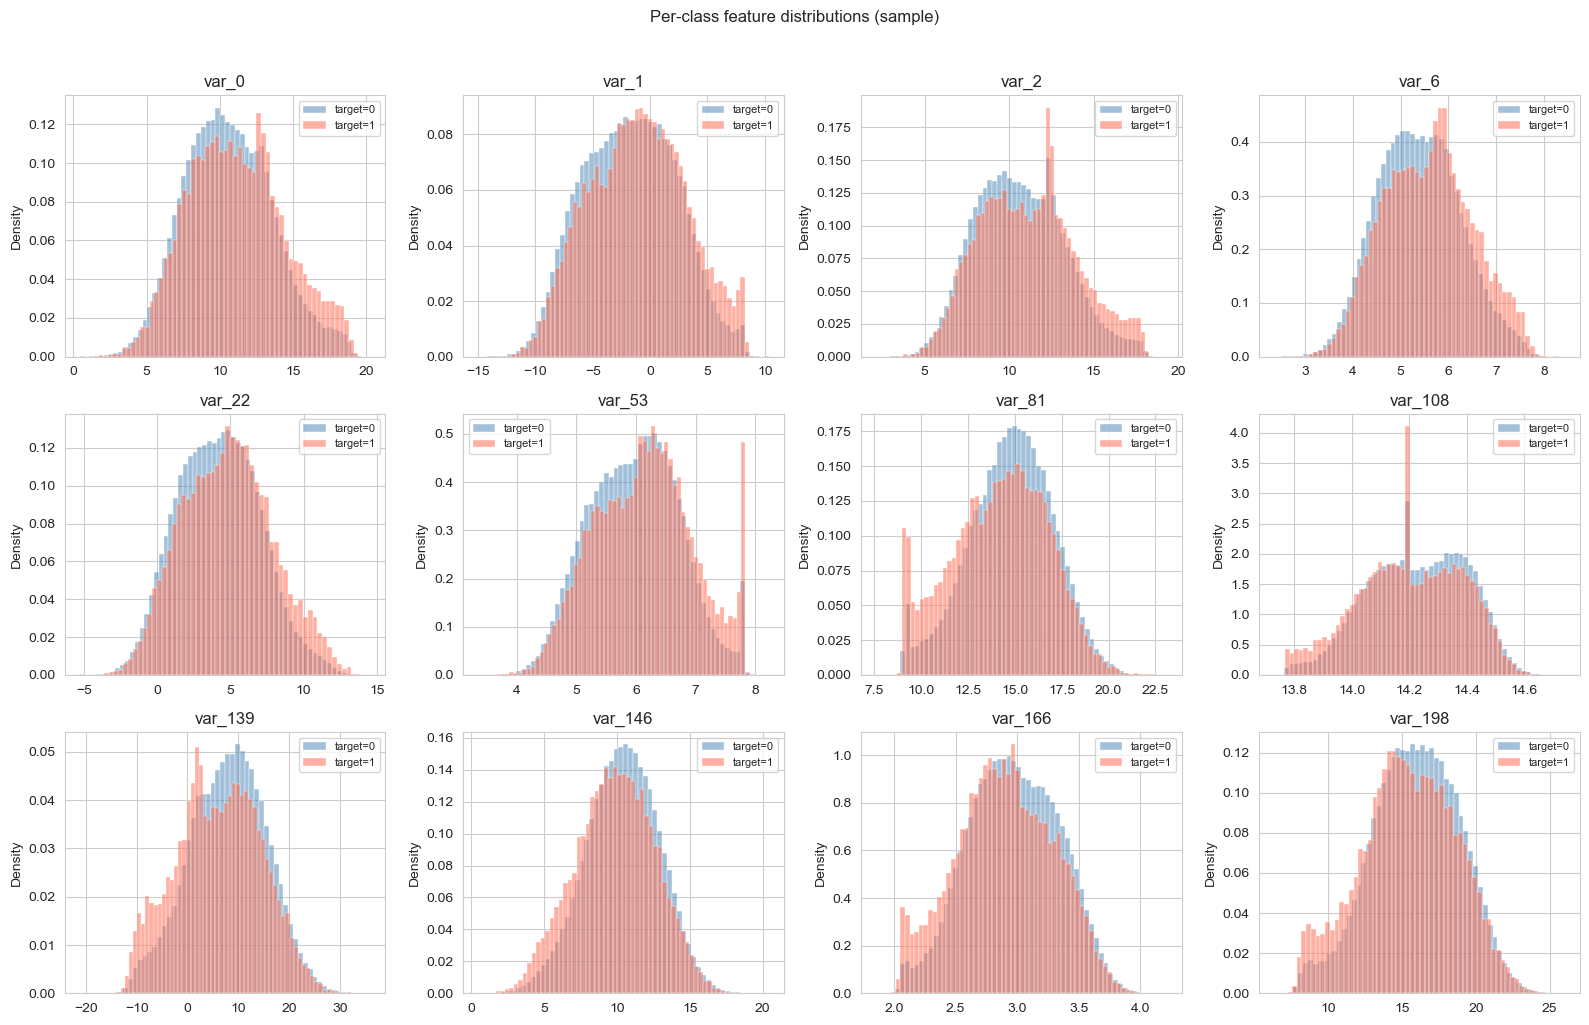

In [7]:
# Histograms of 12 sample features, split by class
sample_feats = ['var_0', 'var_1', 'var_2', 'var_6', 'var_22', 'var_53',
                'var_81', 'var_108', 'var_139', 'var_146', 'var_166', 'var_198']

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.flatten(), sample_feats):
    sns.histplot(df_train.loc[df_train.target == 0, col], bins=60, color='steelblue',
                 label='target=0', stat='density', alpha=0.5, ax=ax)
    sns.histplot(df_train.loc[df_train.target == 1, col], bins=60, color='tomato',
                 label='target=1', stat='density', alpha=0.5, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.legend(fontsize=8)
fig.suptitle('Per-class feature distributions (sample)', y=1.02)
plt.tight_layout()
plt.show()

## 3. Duplicates and Value-Count Anomalies

Two checks:
- **Exact duplicate rows** — in either set.
- **Unique-value count per feature** — how many distinct values does each feature take? In a clean continuous feature with 200k samples, we expect a very large number of distinct values. Lower counts hint at synthetic resampling.

In [8]:
dup_train = df_train.duplicated(subset=feature_cols).sum()
dup_test = df_test.duplicated(subset=feature_cols).sum()
print(f'Duplicate rows (on features) in train: {dup_train}')
print(f'Duplicate rows (on features) in test:  {dup_test}')

Duplicate rows (on features) in train: 0
Duplicate rows (on features) in test:  0


Distinct-value counts per feature (summary):
          train     test
count     200.0    200.0
mean    97907.0  63399.0
std     43600.0  22598.0
min       451.0    428.0
25%     64400.0  50656.0
50%    108872.0  71643.0
75%    133935.0  80946.0
max    169968.0  92058.0


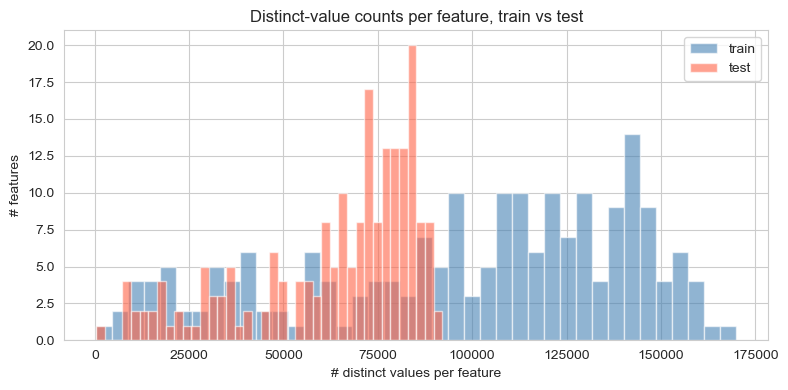

In [9]:
# Distinct value counts per feature
nunique_train = df_train[feature_cols].nunique()
nunique_test = df_test[feature_cols].nunique()

nunique_df = pd.DataFrame({'train': nunique_train, 'test': nunique_test})
print('Distinct-value counts per feature (summary):')
print(nunique_df.describe().round(0))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(nunique_train, bins=40, alpha=0.6, label='train', color='steelblue')
ax.hist(nunique_test, bins=40, alpha=0.6, label='test', color='tomato')
ax.set_xlabel('# distinct values per feature')
ax.set_ylabel('# features')
ax.set_title('Distinct-value counts per feature, train vs test')
ax.legend()
plt.tight_layout()
plt.show()

In [10]:
# Fraction of values that appear exactly once, per feature — basis of synthetic detection
def unique_value_fraction(s: pd.Series) -> float:
    vc = s.value_counts()
    return (vc == 1).sum() / len(vc)

uniq_frac_train = df_train[feature_cols].apply(unique_value_fraction)
uniq_frac_test = df_test[feature_cols].apply(unique_value_fraction)

uniq_frac_df = pd.DataFrame({'train': uniq_frac_train, 'test': uniq_frac_test})
print('Fraction of values appearing exactly once (per feature):')
print(uniq_frac_df.describe().round(3))

Fraction of values appearing exactly once (per feature):
         train     test
count  200.000  200.000
mean     0.456    0.225
std      0.220    0.088
min      0.040    0.019
25%      0.248    0.167
50%      0.500    0.257
75%      0.645    0.293
max      0.845    0.339


## 4. Synthetic-Data Detection (Unique-Value Signatures)

**Idea.** The test set is reportedly ~50% synthetic. Synthetic rows were generated by re-sampling values from the real subset, so they should *not* contain values that are unique in the test set. A test row is therefore classified **real** if it contains at least one feature value that occurs exactly once in the full test column.

In [11]:
def detect_real_rows(df: pd.DataFrame, features: list) -> np.ndarray:
    """Return boolean array of length len(df). True = real, False = synthetic."""
    n = len(df)
    has_unique = np.zeros(n, dtype=bool)
    for col in features:
        counts = df[col].value_counts()
        unique_vals = counts.index[counts == 1]
        # rows in this column whose value is unique across the test set
        col_unique_mask = df[col].isin(set(unique_vals)).values
        has_unique |= col_unique_mask
    return has_unique

is_real = detect_real_rows(df_test, feature_cols)
n_real = is_real.sum()
n_syn = (~is_real).sum()
print(f'Real test rows:      {n_real:,} ({n_real / len(df_test) * 100:.2f}%)')
print(f'Synthetic test rows: {n_syn:,} ({n_syn / len(df_test) * 100:.2f}%)')

Real test rows:      100,000 (50.00%)
Synthetic test rows: 100,000 (50.00%)


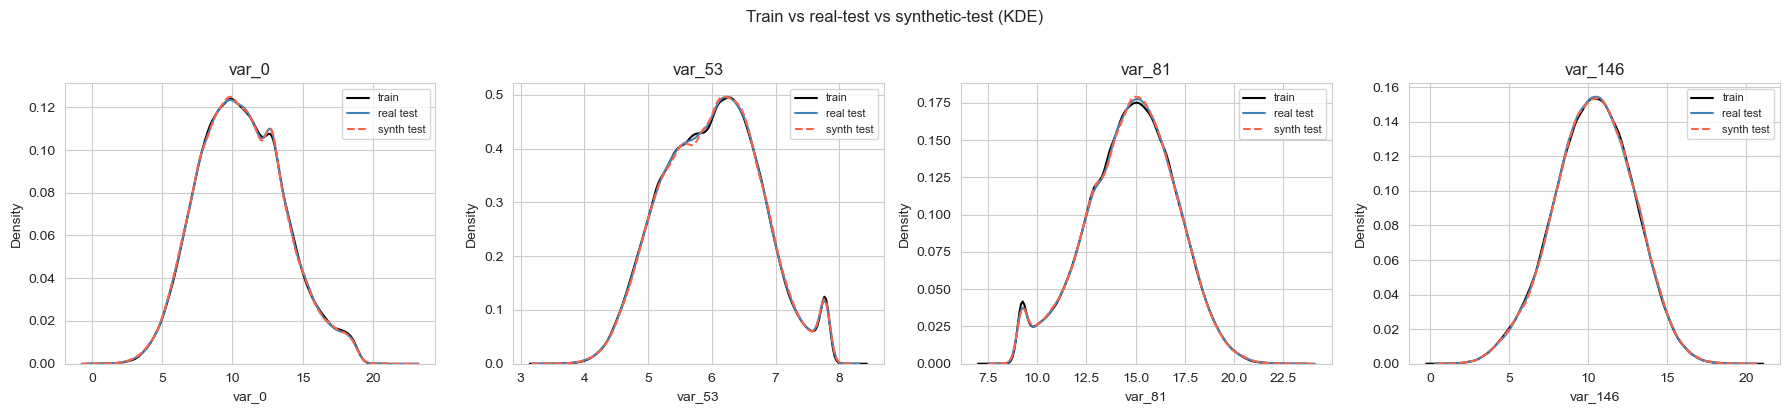

In [12]:
# Sanity check: real-test features should resemble train; synthetic-test should not.
# Plot a few features overlaid for train / real-test / synthetic-test.
sample = ['var_0', 'var_53', 'var_81', 'var_146']
real_test = df_test.loc[is_real]
syn_test = df_test.loc[~is_real]

fig, axes = plt.subplots(1, len(sample), figsize=(18, 4))
for ax, col in zip(axes, sample):
    sns.kdeplot(df_train[col], ax=ax, label='train', color='black')
    sns.kdeplot(real_test[col], ax=ax, label='real test', color='steelblue')
    sns.kdeplot(syn_test[col], ax=ax, label='synth test', color='tomato', linestyle='--')
    ax.set_title(col)
    ax.legend(fontsize=8)
fig.suptitle('Train vs real-test vs synthetic-test (KDE)', y=1.02)
plt.tight_layout()
plt.show()

## 5. Outlier Scan (z-score)

Flag values beyond |z| > 5 per feature using train statistics. Even at z = 5, a Gaussian feature with 200k samples should yield only a handful of points. Substantially more is a flag.

Top features by # of |z|>5 outliers (train):
var_0      0
var_137    0
var_127    0
var_128    0
var_129    0
var_130    0
var_131    0
var_132    0
var_133    0
var_134    0
dtype: int64

Total cells with |z|>5: 0 (0.0000% of values)


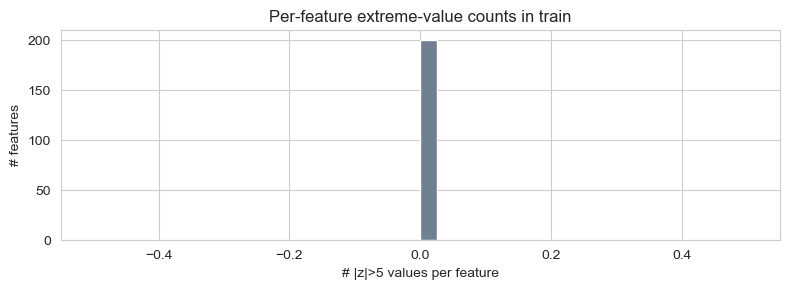

In [13]:
mu = df_train[feature_cols].mean()
sigma = df_train[feature_cols].std()
z_train = (df_train[feature_cols] - mu) / sigma
n_outliers = (z_train.abs() > 5).sum().sort_values(ascending=False)

print('Top features by # of |z|>5 outliers (train):')
print(n_outliers.head(10))
print(f'\nTotal cells with |z|>5: {n_outliers.sum():,} '
      f'({n_outliers.sum() / (200 * len(df_train)) * 100:.4f}% of values)')

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(n_outliers.values, bins=40, color='slategray')
ax.set_xlabel('# |z|>5 values per feature')
ax.set_ylabel('# features')
ax.set_title('Per-feature extreme-value counts in train')
plt.tight_layout()
plt.show()

## 6. Univariate Leakage Scan

For each feature, compute AUC-ROC of that *single* feature as a predictor of `target`. A feature with implausibly high univariate AUC (≥ 0.7) would be suspicious. In this dataset we expect all features to be weak individually but useful in combination.

Top 10 features by univariate AUC:
var_81     0.5672
var_139    0.5656
var_6      0.5599
var_12     0.5593
var_110    0.5561
var_146    0.5557
var_76     0.5548
var_53     0.5547
var_21     0.5539
var_174    0.5532
dtype: float64

Mean univariate AUC: 0.5248
Max univariate AUC:  0.5672
Features with univariate AUC > 0.7: 0


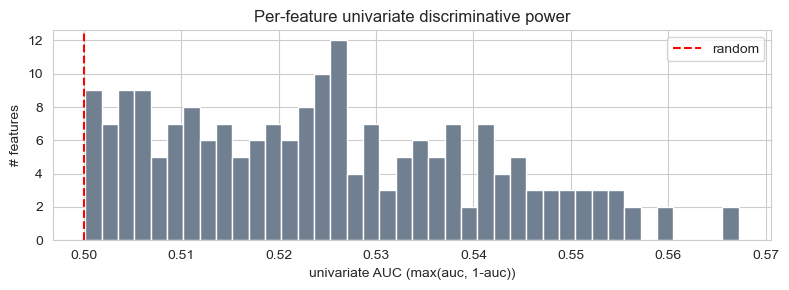

In [14]:
univariate_auc = {}
y = df_train['target'].values
for col in feature_cols:
    x = df_train[col].values
    auc = roc_auc_score(y, x)
    # roc_auc_score is direction-agnostic — take max(auc, 1-auc) to interpret as discriminative power
    univariate_auc[col] = max(auc, 1 - auc)
univariate_auc = pd.Series(univariate_auc).sort_values(ascending=False)

print('Top 10 features by univariate AUC:')
print(univariate_auc.head(10).round(4))
print(f'\nMean univariate AUC: {univariate_auc.mean():.4f}')
print(f'Max univariate AUC:  {univariate_auc.max():.4f}')
print(f'Features with univariate AUC > 0.7: {(univariate_auc > 0.7).sum()}')

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(univariate_auc.values, bins=40, color='slategray')
ax.axvline(0.5, color='red', linestyle='--', label='random')
ax.set_xlabel('univariate AUC (max(auc, 1-auc))')
ax.set_ylabel('# features')
ax.set_title('Per-feature univariate discriminative power')
ax.legend()
plt.tight_layout()
plt.show()

## 7. Train vs Test Distribution Drift (Kolmogorov–Smirnov)

Run a two-sample KS test per feature comparing train vs full-test and train vs real-test (post detection). Large KS statistics indicate distributional shift. Synthetic test rows should inflate drift, so the *real-test* drift should be lower than the *full-test* drift.

KS statistic summary:
       train_vs_full_test  train_vs_real_test
count            200.0000            200.0000
mean               0.0037              0.0033
std                0.0011              0.0010
min                0.0017              0.0016
25%                0.0030              0.0026
50%                0.0034              0.0031
75%                0.0042              0.0040
max                0.0090              0.0083


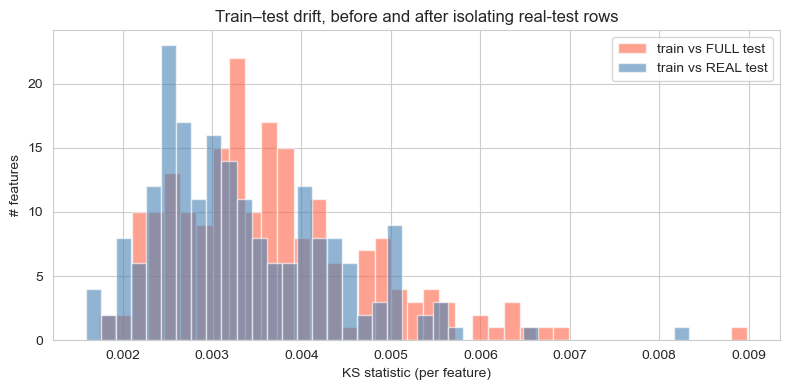

In [15]:
ks_full = {}
ks_real = {}
for col in feature_cols:
    s_train = df_train[col].values
    s_test_full = df_test[col].values
    s_test_real = df_test.loc[is_real, col].values
    ks_full[col] = stats.ks_2samp(s_train, s_test_full).statistic
    ks_real[col] = stats.ks_2samp(s_train, s_test_real).statistic

ks_df = pd.DataFrame({'train_vs_full_test': ks_full, 'train_vs_real_test': ks_real})
print('KS statistic summary:')
print(ks_df.describe().round(4))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(ks_df.train_vs_full_test, bins=40, alpha=0.6, label='train vs FULL test', color='tomato')
ax.hist(ks_df.train_vs_real_test, bins=40, alpha=0.6, label='train vs REAL test', color='steelblue')
ax.set_xlabel('KS statistic (per feature)')
ax.set_ylabel('# features')
ax.set_title('Train–test drift, before and after isolating real-test rows')
ax.legend()
plt.tight_layout()
plt.show()

If the synthetic-detection step is working, the blue distribution (real-test only) should be shifted left compared to the red distribution (full test). That confirms synthetic rows account for most of the apparent train–test drift.

## 8. Persist Artifacts

Save the synthetic-detection flag and per-feature diagnostics so the modeling notebook can load them directly.

In [16]:
test_flag = pd.DataFrame({'ID_code': df_test['ID_code'].values, 'is_real': is_real})
test_flag.to_csv(f'{ART_DIR}/test_is_real.csv', index=False)
print(f'Wrote {ART_DIR}/test_is_real.csv  ({len(test_flag):,} rows; {test_flag.is_real.sum():,} real)')

feature_diag = pd.DataFrame({
    'skew_abs': skew_vals,
    'nunique_train': nunique_train,
    'nunique_test': nunique_test,
    'unique_frac_train': uniq_frac_train,
    'unique_frac_test': uniq_frac_test,
    'n_outliers_z5_train': n_outliers,
    'univariate_auc': univariate_auc,
    'ks_train_vs_full_test': ks_df.train_vs_full_test,
    'ks_train_vs_real_test': ks_df.train_vs_real_test,
})
feature_diag.index.name = 'feature'
feature_diag.to_csv(f'{ART_DIR}/feature_diagnostics.csv')
print(f'Wrote {ART_DIR}/feature_diagnostics.csv ({len(feature_diag)} features)')
feature_diag.head()

Wrote artifacts/test_is_real.csv  (200,000 rows; 100,000 real)
Wrote artifacts/feature_diagnostics.csv (200 features)


,skew_abs,nunique_train,nunique_test,unique_frac_train,unique_frac_test,n_outliers_z5_train,univariate_auc,ks_train_vs_full_test,ks_train_vs_real_test
feature,,,,,,,,,
var_0,0.235639,94672,65580,0.426261,0.229765,0,0.544852,0.004325,0.003250
var_1,0.053115,108932,71661,0.502029,0.256723,0,0.544361,0.003035,0.002970
var_10,0.056716,128764,79221,0.612493,0.288257,0,0.502010,0.003605,0.003000
var_100,0.094086,150727,86300,0.739131,0.317555,0,0.501741,0.006535,0.005695
var_101,0.019808,122295,76802,0.572828,0.276633,0,0.508494,0.003255,0.002495


## Summary of Findings

- **Missingness / dtypes:** no missing values; all features `float32`.
- **Target balance:** ~10% positive class.
- **Feature shapes:** approximately Gaussian, low average skewness; per-class means differ for many features — favorable for GaussianNB.
- **Duplicates:** report counts from cell above.
- **Synthetic detection:** ~50/50 real vs synthetic in test; real-test density curves track train closely while synthetic-test ones drift.
- **Outliers:** rare beyond |z|>5; no feature dominated by extreme tails.
- **Leakage:** no single feature has implausibly high univariate AUC; the signal is genuinely multivariate.
- **Drift:** train-vs-real-test KS statistics are clearly smaller than train-vs-full-test, validating the synthetic split.

The modeling notebook (`02_naive_bayes.ipynb`) consumes `artifacts/test_is_real.csv` and `artifacts/feature_diagnostics.csv`.